<a href="https://colab.research.google.com/github/spbromberg/Project-3-DS-4002/blob/main/Scripts/03_Analysis_Paintings_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Paintings Project - Analysis
## Group 5 - DS 4002


**Notebook Overview:**

This notebook cleans 550 WikiArt paintings, resizes them to 224 x 224 pixels, and splits them by artist. It trains a ResNet-18 model to classify six artistic movements and evaluates its performance against a majority-class baseline using accuracy, macro-F1, per-class results, a confusion matrix, and a Grad-CAM example.

Imports

In [1]:
# General tools
import os
import zipfile
import copy

# Data handling
import numpy as np
import pandas as pd
from PIL import Image, ImageOps

# PyTorch and image transforms
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

# Evaluation and plots
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Create Outputs Folder
OUTPUT_DIR = "Output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

Image & Data Cleaning

In [5]:
CSV_PATH = "/content/wikiart_paintings.csv"
ZIP_PATH = "/content/wikiart_images_complete.zip"
DATA_DIR = "/content/wikiart_data"
CLEAN_DIR = "/content/wikiart_cleaned"

# Extract the image ZIP file.
os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

# Load the painting information.
df = pd.read_csv(CSV_PATH)

clean_paths = []
readable_rows = []
bad_images = []

for index, row in df.iterrows():
    original_path = os.path.join(DATA_DIR, row["image_path"])

    try:
        with Image.open(original_path) as image:
            image = image.convert("RGB")
            image = ImageOps.pad(
                image,
                (224, 224),
                method=Image.Resampling.LANCZOS,
                color=(255, 255, 255)
            )

        # Save each cleaned image using its original relative folder path.
        relative_path = os.path.splitext(row["image_path"])[0] + ".jpg"
        cleaned_path = os.path.join(CLEAN_DIR, relative_path)
        os.makedirs(os.path.dirname(cleaned_path), exist_ok=True)
        image.save(cleaned_path, format="JPEG", quality=95)

        readable_rows.append(index)
        clean_paths.append(cleaned_path)

    except Exception as error:
        bad_images.append((row["image_path"], str(error)))

# Exclude rows whose images could not be opened and cleaned.
df = df.loc[readable_rows].copy().reset_index(drop=True)
df["full_image_path"] = clean_paths

print("Usable paintings:", len(df))
print("Unreadable images excluded:", len(bad_images))
print("\nPaintings per movement:")
print(df["movement"].value_counts())

if bad_images:
    print("\nImages that could not be cleaned:")
    for path, error in bad_images:
        print(path, "—", error)

print("\nCleaned data preview:")
display(df.head())

Usable paintings: 550
Unreadable images excluded: 0

Paintings per movement:
movement
Renaissance      100
Baroque          100
Impressionism    100
Romanticism       92
Other             88
Cubism            70
Name: count, dtype: int64

Cleaned data preview:


,title,artist_name,artist_slug,movement,artwork_styles,medium,artwork_url,image_url,image_path,full_image_path
0,Butcher's Stall with the Flight into Egypt,Pieter Aertsen,pieter-aertsen,Renaissance,Northern Renaissance,oil,https://www.wikiart.org/en/pieter-aertsen/butc...,https://uploads6.wikiart.org/images/pieter-aer...,images/pieter-aertsen--butcher-s-stall-with-th...,/content/wikiart_cleaned/images/pieter-aertsen...
1,The Egg Dance,Pieter Aertsen,pieter-aertsen,Renaissance,Northern Renaissance,oil; wood,https://www.wikiart.org/en/pieter-aertsen/the-...,https://uploads4.wikiart.org/images/pieter-aer...,images/pieter-aertsen--the-egg-dance-1552.jpg,/content/wikiart_cleaned/images/pieter-aertsen...
2,Cook in front of the Stove,Pieter Aertsen,pieter-aertsen,Renaissance,Northern Renaissance,oil; panel,https://www.wikiart.org/en/pieter-aertsen/cook...,https://uploads8.wikiart.org/images/pieter-aer...,images/pieter-aertsen--cook-in-front-of-the-st...,/content/wikiart_cleaned/images/pieter-aertsen...
3,The Cook,Pieter Aertsen,pieter-aertsen,Renaissance,Northern Renaissance,oil; panel,https://www.wikiart.org/en/pieter-aertsen/the-...,https://uploads8.wikiart.org/images/pieter-aer...,images/pieter-aertsen--the-cook-1559.jpg,/content/wikiart_cleaned/images/pieter-aertsen...
4,Peasants by the Hearth,Pieter Aertsen,pieter-aertsen,Renaissance,Northern Renaissance,oil; wood,https://www.wikiart.org/en/pieter-aertsen/peas...,https://uploads4.wikiart.org/images/pieter-aer...,images/pieter-aertsen--peasants-by-the-hearth-...,/content/wikiart_cleaned/images/pieter-aertsen...


Apply Training, Test, & Validation Splits to Data

split          test  train  validation
movement                              
Baroque           5     86           9
Cubism            3     54          13
Impressionism    20     78           2
Other             7     63          18
Renaissance      30     55          15
Romanticism      19     61          12


split,test,train,validation
movement,,,
Baroque,5,86,9
Cubism,3,54,13
Impressionism,20,78,2
Other,7,63,18
Renaissance,30,55,15
Romanticism,19,61,12


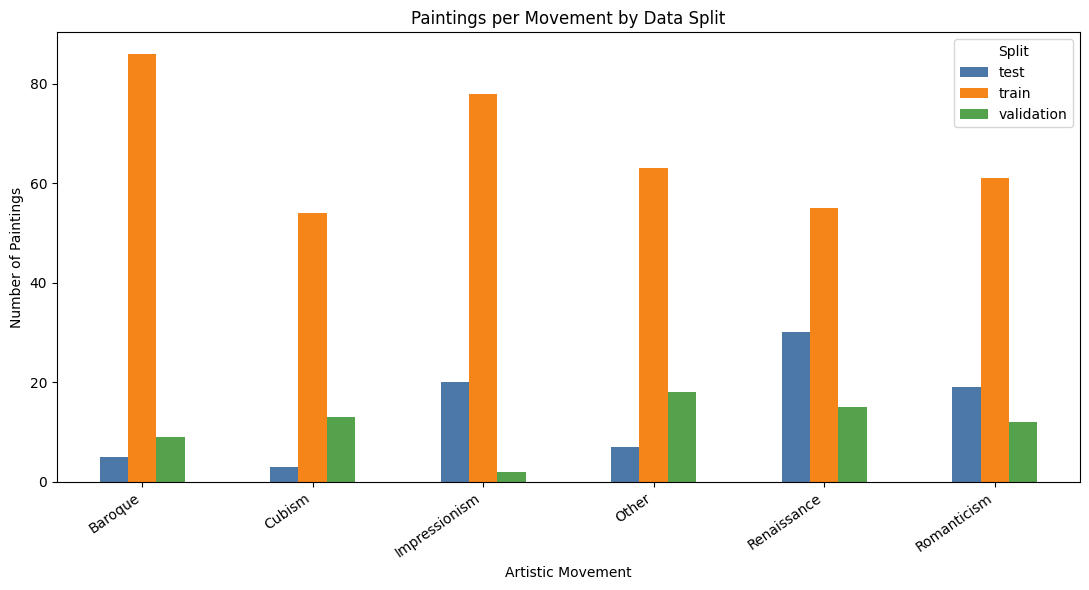

In [6]:
from sklearn.model_selection import StratifiedGroupKFold

df = df.reset_index(drop=True)

class_names = sorted(df["movement"].unique())
class_to_number = {name: number for number, name in enumerate(class_names)}
df["label"] = df["movement"].map(class_to_number)

# Hold out one fold for testing, keeping each artist in just one split.
test_splitter = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)
trainval_idx, test_idx = next(
    test_splitter.split(df, df["movement"], groups=df["artist_slug"])
)

trainval_df = df.iloc[trainval_idx].copy()
test_df = df.iloc[test_idx].copy()

# Split the remaining data into training and validation sets.
val_splitter = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=43
)
train_idx, val_idx = next(
    val_splitter.split(
        trainval_df,
        trainval_df["movement"],
        groups=trainval_df["artist_slug"]
    )
)

train_df = trainval_df.iloc[train_idx].copy()
val_df = trainval_df.iloc[val_idx].copy()

# Record the split names in the full dataframe.
df["split"] = "train"
df.loc[val_df.index, "split"] = "validation"
df.loc[test_df.index, "split"] = "test"

# Confirm artists do not cross splits.
assert set(train_df["artist_slug"]).isdisjoint(val_df["artist_slug"])
assert set(train_df["artist_slug"]).isdisjoint(test_df["artist_slug"])
assert set(val_df["artist_slug"]).isdisjoint(test_df["artist_slug"])

print(pd.crosstab(df["movement"], df["split"]))

split_counts = pd.crosstab(df["movement"], df["split"])
display(split_counts)

split_counts.to_csv(
    os.path.join(OUTPUT_DIR, "class_counts_by_split.csv")
)

ax = split_counts.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#4C78A8", "#F58518", "#54A24B"]
)

ax.set_title("Paintings per Movement by Data Split")
ax.set_xlabel("Artistic Movement")
ax.set_ylabel("Number of Paintings")
ax.legend(title="Split")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "class_counts_by_split.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Create PyTorch Dataset & DataLoader

In [7]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Normalize images for the pretrained ResNet-18 model.
image_mean = [0.485, 0.456, 0.406]
image_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomRotation(5, fill=255),
    transforms.ToTensor(),
    transforms.Normalize(image_mean, image_std)
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(image_mean, image_std)
])

class PaintingDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image = Image.open(row["full_image_path"]).convert("RGB")
        image = self.transform(image)
        label = int(row["label"])
        return image, label

train_dataset = PaintingDataset(train_df, train_transform)
val_dataset = PaintingDataset(val_df, eval_transform)
test_dataset = PaintingDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True, num_workers=2,
    pin_memory=(device.type == "cuda")
)
val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False, num_workers=2,
    pin_memory=(device.type == "cuda")
)
test_loader = DataLoader(
    test_dataset, batch_size=16, shuffle=False, num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Using device: cpu
Training batches: 25
Validation batches: 5
Test batches: 6


Establish Majority Class Baseline

In [8]:
from sklearn.metrics import accuracy_score, f1_score

# Find the most common movement in the training data.
majority_class = train_df["movement"].mode()[0]

# Predict that movement for every painting in the test set.
baseline_predictions = [majority_class] * len(test_df)

# Compare the baseline predictions with the actual test labels.
baseline_accuracy = accuracy_score(
    test_df["movement"],
    baseline_predictions
)
baseline_macro_f1 = f1_score(
    test_df["movement"],
    baseline_predictions,
    average="macro",
    zero_division=0
)

print("Majority class:", majority_class)
print(f"Baseline test accuracy: {baseline_accuracy:.3f}")
print(f"Baseline test macro-F1: {baseline_macro_f1:.3f}")

Majority class: Baroque
Baseline test accuracy: 0.060
Baseline test macro-F1: 0.019


Create Majority-Class Baseline (For Comparison with ResNet-18 Later)

In [9]:
majority_class = train_df["movement"].mode()[0]
print("Majority class:", majority_class)

Majority class: Baroque


Setup ResNet-18 Model for Analysis

In [10]:
# Load ResNet-18 with pretrained ImageNet weights.
model = resnet18(weights=ResNet18_Weights.DEFAULT)

# Freeze the pretrained layers first.
for parameter in model.parameters():
    parameter.requires_grad = False

# Replace the final layer for our art movement classes.
model.fc = nn.Linear(model.fc.in_features, len(class_names))

# Fine-tune the last ResNet block as well as the new classifier.
for parameter in model.layer4.parameters():
    parameter.requires_grad = True

model = model.to(device)

# Calculate class weights in case you want to compare weighted loss.
class_counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
    .to_numpy()
)

class_weights = len(train_df) / (len(class_names) * class_counts)
class_weights = torch.tensor(
    class_weights, dtype=torch.float32
).to(device)

# Start with unweighted loss when optimizing overall accuracy.
# Change False to True for a separate weighted-loss run.
USE_CLASS_WEIGHTS = False
weights_for_loss = class_weights if USE_CLASS_WEIGHTS else None
loss_function = nn.CrossEntropyLoss(weight=weights_for_loss)

# Use a small learning rate for pretrained features and a larger one for the new layer.
optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(), "lr": 1e-3}
])

print("Model ready.")
print("Classes:", class_names)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 142MB/s]


Model ready.
Classes: ['Baroque', 'Cubism', 'Impressionism', 'Other', 'Renaissance', 'Romanticism']


Train ResNet-18 Model & Use Validation Set to Preserve the Best Version

(Test Set Reamins Untouched Until Final Evaluation)

In [11]:
EPOCHS = 8
best_val_accuracy = -1
best_model_state = copy.deepcopy(model.state_dict())
history = []

for epoch in range(EPOCHS):
    # Train the model. Batch-normalization layers stay in evaluation mode.
    model.eval()
    model.fc.train()
    total_train_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    # Measure performance on the validation set.
    model.eval()
    val_predictions = []
    val_actual = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            outputs = model(images)
            predictions = outputs.argmax(dim=1).cpu().tolist()

            val_predictions.extend(predictions)
            val_actual.extend(labels.tolist())

    val_accuracy = accuracy_score(val_actual, val_predictions)
    val_macro_f1 = f1_score(
        val_actual,
        val_predictions,
        average="macro",
        zero_division=0
    )

    average_loss = total_train_loss / len(train_loader)

    history.append({
    "epoch": epoch + 1,
    "training_loss": average_loss,
    "validation_accuracy": val_accuracy,
    "validation_macro_f1": val_macro_f1
})

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Training loss: {average_loss:.3f} | "
        f"Validation accuracy: {val_accuracy:.3f} | "
        f"Validation macro-F1: {val_macro_f1:.3f}"
    )

    # Save the model whenever validation accuracy improves.
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_model_state = copy.deepcopy(model.state_dict())

# Restore the version with the best validation accuracy.
model.load_state_dict(best_model_state)
print(f"\nBest validation accuracy: {best_val_accuracy:.3f}")

Epoch 1/8 | Training loss: 1.617 | Validation accuracy: 0.275 | Validation macro-F1: 0.265
Epoch 2/8 | Training loss: 1.136 | Validation accuracy: 0.391 | Validation macro-F1: 0.340
Epoch 3/8 | Training loss: 0.895 | Validation accuracy: 0.333 | Validation macro-F1: 0.270
Epoch 4/8 | Training loss: 0.701 | Validation accuracy: 0.377 | Validation macro-F1: 0.337
Epoch 5/8 | Training loss: 0.553 | Validation accuracy: 0.406 | Validation macro-F1: 0.371
Epoch 6/8 | Training loss: 0.472 | Validation accuracy: 0.435 | Validation macro-F1: 0.415
Epoch 7/8 | Training loss: 0.365 | Validation accuracy: 0.391 | Validation macro-F1: 0.359
Epoch 8/8 | Training loss: 0.264 | Validation accuracy: 0.406 | Validation macro-F1: 0.381

Best validation accuracy: 0.435


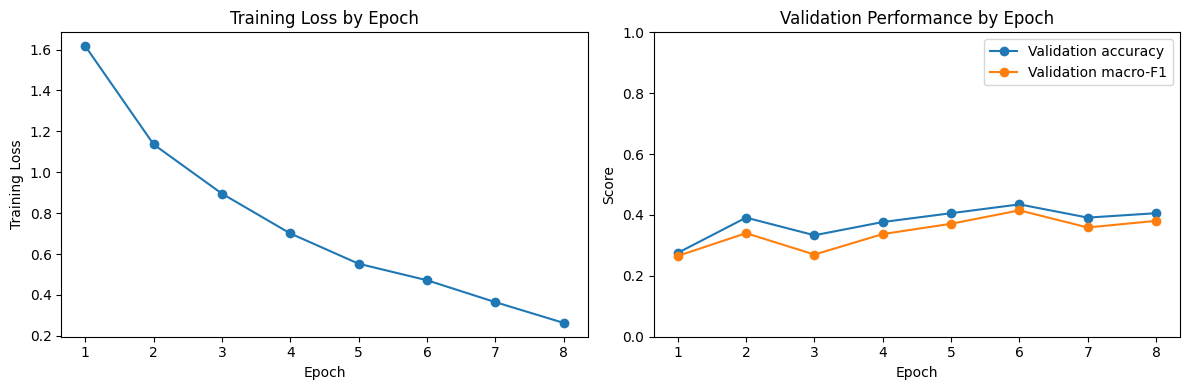

In [12]:
history_df = pd.DataFrame(history)
history_df.to_csv(
    os.path.join(OUTPUT_DIR, "training_history.csv"),
    index=False
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_df["epoch"],
    history_df["training_loss"],
    marker="o"
)
axes[0].set_title("Training Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training Loss")

axes[1].plot(
    history_df["epoch"],
    history_df["validation_accuracy"],
    marker="o",
    label="Validation accuracy"
)
axes[1].plot(
    history_df["epoch"],
    history_df["validation_macro_f1"],
    marker="o",
    label="Validation macro-F1"
)
axes[1].set_title("Validation Performance by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "training_history.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Evaluate Best Version of the Model on the Untouchued Test Set

(Reports Final Accuracy, Macro-F1, Per-Class Precision, & Confusion Matrix)

Test accuracy: 0.405
Test macro-F1: 0.380

Per-class results:
               precision    recall  f1-score   support

      Baroque       0.14      0.20      0.17         5
       Cubism       0.50      1.00      0.67         3
Impressionism       0.73      0.55      0.63        20
        Other       0.00      0.00      0.00         7
  Renaissance       0.80      0.40      0.53        30
  Romanticism       0.23      0.37      0.29        19

     accuracy                           0.40        84
    macro avg       0.40      0.42      0.38        84
 weighted avg       0.54      0.40      0.44        84



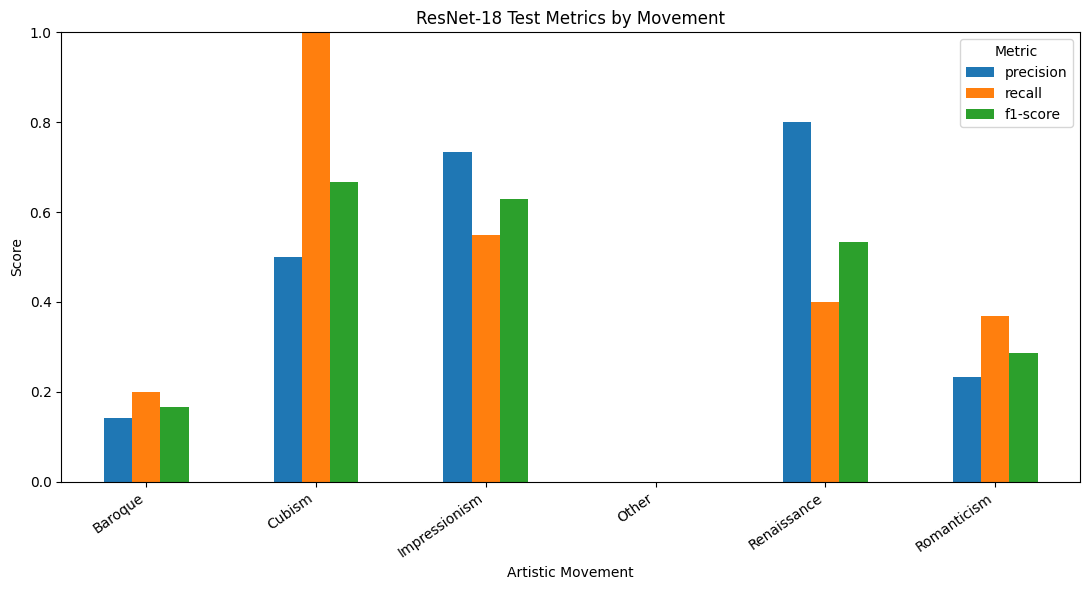

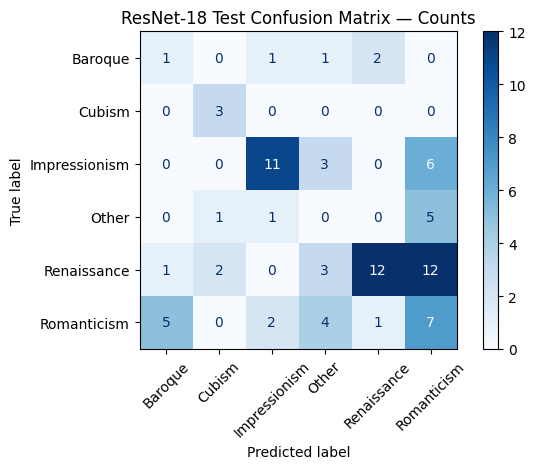

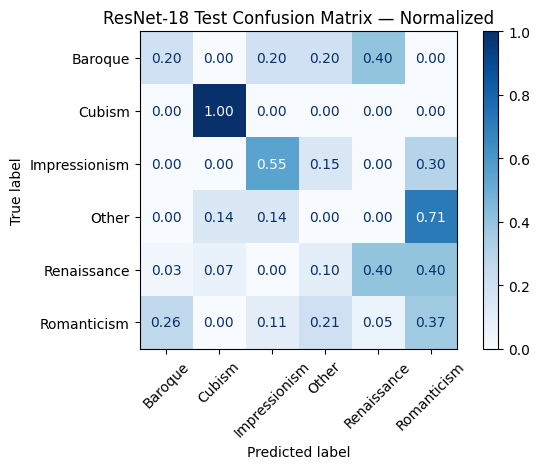

In [13]:
model.eval()

test_predictions = []
test_actual = []
test_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        test_predictions.extend(predictions.cpu().tolist())
        test_actual.extend(labels.tolist())
        test_probabilities.extend(probabilities.cpu().tolist())

test_accuracy = accuracy_score(test_actual, test_predictions)
test_macro_f1 = f1_score(
    test_actual,
    test_predictions,
    average="macro",
    zero_division=0
)

print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test macro-F1: {test_macro_f1:.3f}")

# Save the per-class precision, recall, F1, and support.
report_dict = classification_report(
    test_actual,
    test_predictions,
    labels=range(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).T
report_df.to_csv(
    os.path.join(OUTPUT_DIR, "test_classification_report.csv"),
    index=True
)

print("\nPer-class results:")
print(classification_report(
    test_actual,
    test_predictions,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# Plot per-class precision, recall, and F1.
class_metrics = report_df.loc[
    class_names, ["precision", "recall", "f1-score", "support"]
].copy()
class_metrics.index.name = "movement"
class_metrics = class_metrics.reset_index()

class_metrics.to_csv(
    os.path.join(OUTPUT_DIR, "per_class_metrics.csv"),
    index=False
)

ax = class_metrics.set_index("movement")[
    ["precision", "recall", "f1-score"]
].plot(kind="bar", figsize=(11, 6))

ax.set_title("ResNet-18 Test Metrics by Movement")
ax.set_xlabel("Artistic Movement")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Metric")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "per_class_metrics.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Plot the confusion matrix as raw counts.
matrix = confusion_matrix(
    test_actual,
    test_predictions,
    labels=range(len(class_names))
)

count_display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=class_names
)
count_display.plot(cmap="Blues", values_format="d", xticks_rotation=45)
plt.title("ResNet-18 Test Confusion Matrix — Counts")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix_counts.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Plot the confusion matrix as row percentages.
normalized_matrix = confusion_matrix(
    test_actual,
    test_predictions,
    labels=range(len(class_names)),
    normalize="true"
)

normalized_display = ConfusionMatrixDisplay(
    confusion_matrix=normalized_matrix,
    display_labels=class_names
)
normalized_display.plot(cmap="Blues", values_format=".2f", xticks_rotation=45)
plt.title("ResNet-18 Test Confusion Matrix — Normalized")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix_normalized.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Save each test painting's actual and predicted movement.
test_details = test_df.reset_index(drop=True).copy()
probability_array = np.array(test_probabilities)

test_details["actual_movement"] = [
    class_names[label] for label in test_actual
]
test_details["predicted_movement"] = [
    class_names[label] for label in test_predictions
]
test_details["prediction_confidence"] = probability_array.max(axis=1)
test_details["correct"] = (
    test_details["actual_movement"] == test_details["predicted_movement"]
)

columns_to_save = [
    column for column in [
        "title",
        "artist_name",
        "image_path",
        "actual_movement",
        "predicted_movement",
        "prediction_confidence",
        "correct"
    ]
    if column in test_details.columns
]

test_details[columns_to_save].to_csv(
    os.path.join(OUTPUT_DIR, "test_predictions.csv"),
    index=False
)

Example Predictions

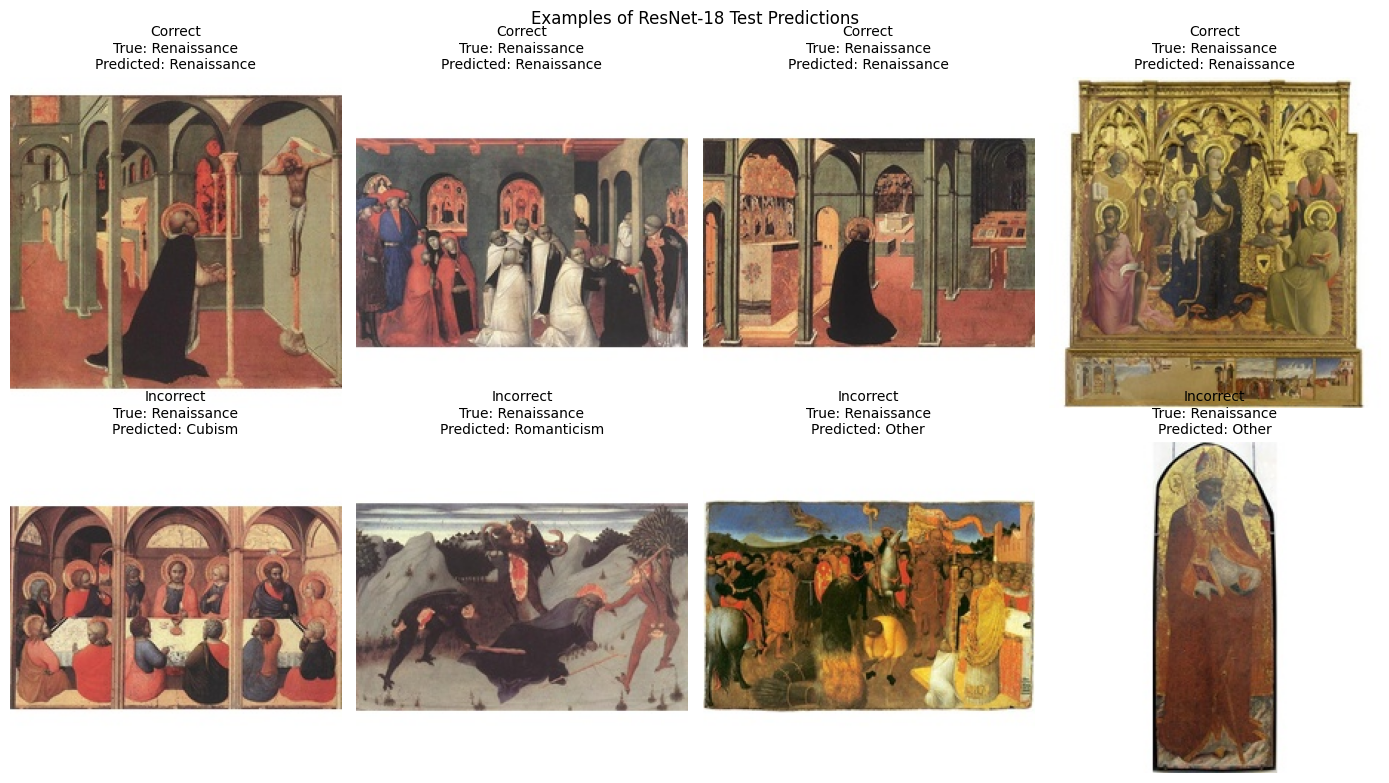

In [14]:
correct_indices = np.flatnonzero(test_details["correct"].to_numpy())
incorrect_indices = np.flatnonzero(~test_details["correct"].to_numpy())

selected_indices = list(correct_indices[:4]) + list(incorrect_indices[:4])

if selected_indices:
    ncols = 4
    nrows = int(np.ceil(len(selected_indices) / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(14, 4 * nrows)
    )
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, index in zip(axes, selected_indices):
        row = test_details.iloc[index]

        with Image.open(row["full_image_path"]) as image:
            ax.imshow(image.convert("RGB"))

        status = "Correct" if row["correct"] else "Incorrect"
        ax.set_title(
            f"{status}\nTrue: {row['actual_movement']}\n"
            f"Predicted: {row['predicted_movement']}",
            fontsize=10
        )
        ax.axis("off")

    plt.suptitle("Examples of ResNet-18 Test Predictions")
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, "prediction_examples.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
else:
    print("No test examples were available to display.")

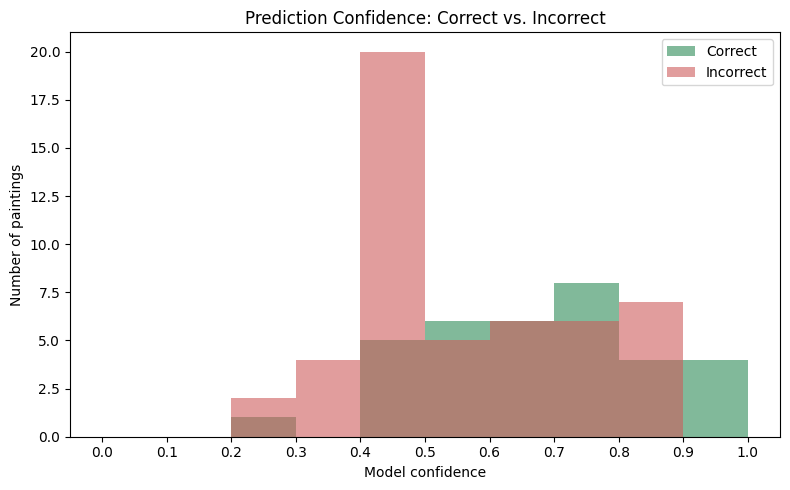

In [15]:
plt.figure(figsize=(8, 5))

for is_correct, label, color in [
    (True, "Correct", "seagreen"),
    (False, "Incorrect", "indianred")
]:
    values = test_details.loc[
        test_details["correct"] == is_correct,
        "prediction_confidence"
    ]
    plt.hist(
        values,
        bins=np.linspace(0, 1, 11),
        alpha=0.6,
        label=label,
        color=color
    )

plt.title("Prediction Confidence: Correct vs. Incorrect")
plt.xlabel("Model confidence")
plt.ylabel("Number of paintings")
plt.xticks(np.linspace(0, 1, 11))
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "confidence_by_correctness.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Grad-CAM Visualization

(Inspects Which Aspects of the Test Paintings Influence the Model's Prediction)

Actual movement: Renaissance
Predicted movement: Cubism


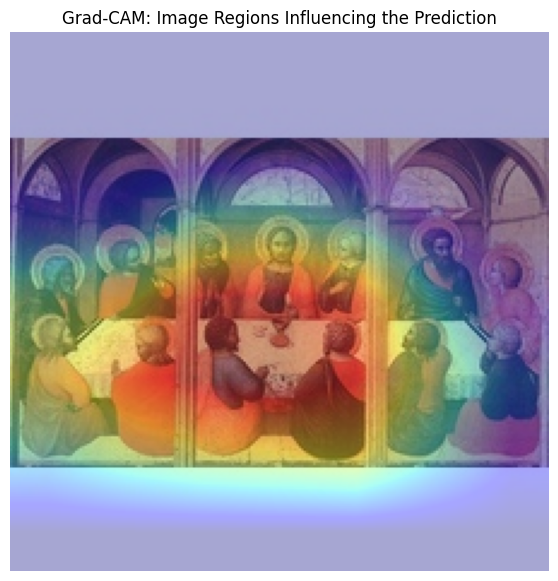

In [16]:
# Select a painting from the test set.
example = test_df.iloc[0]
original_image = Image.open(example["full_image_path"]).convert("RGB")
input_tensor = eval_transform(original_image).unsqueeze(0).to(device)

# Enable gradient tracking on the input tensor for Grad-CAM
input_tensor.requires_grad_(True)

# Store the layer's activations and their gradients.
activations = []
gradients = []

def save_activation(module, inputs, output):
    activations.append(output)
    output.register_hook(lambda gradient: gradients.append(gradient))

# Use the final ResNet block for Grad-CAM.
hook = model.layer4[-1].register_forward_hook(save_activation)

model.eval()
model.zero_grad()

scores = model(input_tensor)
predicted_label = scores.argmax(dim=1).item()

# Calculate gradients for the predicted class.
scores[0, predicted_label].backward()

activation = activations[0]
gradient = gradients[0]

# Weight feature maps by their average gradients.
weights = gradient.mean(dim=(2, 3), keepdim=True)
heatmap = F.relu((weights * activation).sum(dim=1, keepdim=True))

# Resize the heatmap to match the painting.
heatmap = F.interpolate(
    heatmap,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)
heatmap = heatmap.squeeze().detach().cpu().numpy()
heatmap = heatmap / (heatmap.max() + 1e-8)

hook.remove()

print("Actual movement:", example["movement"])
print("Predicted movement:", class_names[predicted_label])

plt.figure(figsize=(7, 7))
plt.imshow(original_image.resize((224, 224)))
plt.imshow(heatmap, cmap="jet", alpha=0.35)
plt.axis("off")
plt.title("Grad-CAM: Image Regions Influencing the Prediction")
plt.savefig(
    os.path.join(OUTPUT_DIR, "gradcam_example.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Final Model Comparison with Baseline

In [17]:
# Score the baseline on the test set after model selection is complete.
baseline_label = class_to_number[majority_class]
baseline_predictions = [baseline_label] * len(test_actual)

baseline_accuracy = accuracy_score(test_actual, baseline_predictions)
baseline_macro_f1 = f1_score(
    test_actual,
    baseline_predictions,
    labels=range(len(class_names)),
    average="macro",
    zero_division=0
)

results = pd.DataFrame({
    "Model": ["Majority-class baseline", "ResNet-18"],
    "Test accuracy": [baseline_accuracy, test_accuracy],
    "Test macro-F1": [baseline_macro_f1, test_macro_f1]
})

results.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)

# Explicitly use IPython's display to avoid the overwritten variable name conflict
import IPython
IPython.display.display(results)

,Model,Test accuracy,Test macro-F1
0,Majority-class baseline,0.059524,0.018727
1,ResNet-18,0.404762,0.380159


Download Ouptus

In [19]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/project3_outputs",
    "zip",
    root_dir=OUTPUT_DIR
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>